# 02 · Exploratory analysis — what makes a transfer flop?

**Input:** `data/processed/transfers_model.csv.gz` from notebook 01 (one row = one permanent summer transfer;
`y_flop = 1` if the player played < 25 % of his new club's matches in the first season).

**Goal of this notebook.** Before any modelling, find out *which* factors are really related to flops, how big
the effects are, and which "obvious" patterns are traps. Everything here feeds the model in notebook 03.

### Hypotheses (written down *before* looking at the adjusted results)

| # | Hypothesis | Expected direction of flop risk |
|---|---|---|
| H1 | Young players (under 23) flop more | ↑ |
| H2 | Players who played little last season flop more | ↑ for low playing time |
| H3 | Stepping **up** a tier (e.g. 2nd division → 1st) raises risk | ↑ |
| H4 | A **stronger destination club** (higher points per game last season) raises risk, even within the same tier | ↑ |
| H5 | More established players in the same position at the destination raise risk | ↑ |
| H6 | "Money buys minutes": paying above market value lowers risk | ↓ |
| H7 | Higher-valued players flop less | ↓ |
| H8 | Recent injuries raise risk | ↑ |
| H9 | Goalkeepers flop more (only one can play) | ↑ |

Method: (1) look at raw rates with confidence intervals, (2) fit one **adjusted** logistic regression so that
overlapping factors (age, value, tier, position…) are separated, (3) check how the conclusions behave across
time, missing data and small samples.

## 1 · Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter, PercentFormatter
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
DATA = f"{ROOT}/data/processed/transfers_model.csv.gz"
FIG_DIR, TAB_DIR = f"{ROOT}/reports/figures", f"{ROOT}/reports/tables"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)
assert os.path.exists(DATA), "Run notebook 01 first - it creates data/processed/transfers_model.csv.gz"

# --- chart style: one accent colour, grey for context, thin marks, solid hairline grid -----------------
SURFACE, INK, INK2, GRID, GRAY = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1", "#b9b8b2"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
BLUE_LIGHT = "#86b6ef"
SEQ_BLUES = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
             "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.5, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=160, bbox_inches="tight")

d = pd.read_csv(DATA)
P0 = d["y_flop"].mean()
print(f"{len(d):,} transfers | overall flop rate {P0:.1%} | seasons {d.season_y.min()}-{d.season_y.max()}")

44,580 transfers | overall flop rate 20.0% | seasons 2012-2024


In [2]:
# Derived columns used throughout this notebook (all computed from pre-transfer features only)
d["gk"] = (d["main_position"] == "Goalkeeper").astype(int)
age_floor = np.floor(d["age"])
d["age_grp"] = np.select([age_floor <= 22, age_floor >= 30], ["u23", "30plus"], default="23_29")
d["dest_tier"] = d["dest_level"].clip(upper=3)

def rate_table(cat):
    """Flop rate with a 95% Wilson confidence interval per category."""
    g = d.groupby(cat, observed=True)["y_flop"].agg(k="sum", n="size")
    g["rate"] = g["k"] / g["n"]
    g["lo"], g["hi"] = proportion_confint(g["k"], g["n"], alpha=0.05, method="wilson")
    return g

def rate_bars(ax, cat, title):
    g = rate_table(cat)
    x = np.arange(len(g))
    ax.bar(x, g["rate"], width=0.42, color=BLUE, zorder=3)
    ax.errorbar(x, g["rate"], yerr=[g["rate"] - g["lo"], g["hi"] - g["rate"]], fmt="none",
                ecolor=INK2, elinewidth=1, capsize=3, zorder=4)
    ax.axhline(P0, color=GRAY, lw=1, zorder=2)
    ax.set_xticks(x); ax.set_xticklabels([f"{i}\nn={n:,}" for i, n in zip(g.index, g["n"])], fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    return g

## 2 · The target, and how fragile it is

The 25 % cut-off is a modelling choice. Before trusting any pattern we check that the main drivers look the same with
a stricter or looser definition, and when the ~8 % of transfers with **zero** appearances are removed (some of these
players may have played only for a reserve team — see limitations in notebook 01).

`AUC` below means: if we rank transfers by that single rule alone, how often does a flop rank above a non-flop
(0.5 = coin flip, 1.0 = perfect). It is a quick way to compare the strength of simple rules.

In [3]:
rules = {                       # a single feature used as a "risk score": higher score = riskier
    "young (-age)":            -d["age"],
    "low last-season playing time": -d["prev1_share"],
    "step up in tier":          d["tier_change"],
    "goalkeeper":               d["gk"],
}

def rule_aucs(y, mask):
    out = {}
    for name, score in rules.items():
        m = mask & score.notna()
        out[name] = roc_auc_score(y[m], score[m])
    return out

rows = []
for thr in [0.15, 0.25, 0.33]:
    y = (d["share_after"] < thr).astype(int)
    rows.append({"definition": f"flop = plays < {thr:.0%}", "flop_rate": y.mean(), **rule_aucs(y, pd.Series(True, index=d.index))})
y = d["y_flop"]; keep = d["apps_after"] > 0
rows.append({"definition": "flop = < 25 %, zero-appearance rows excluded", "flop_rate": y[keep].mean(), **rule_aucs(y, keep)})
sens = pd.DataFrame(rows).set_index("definition")
sens.round(3)

,flop_rate,young (-age),low last-season playing time,step up in tier,goalkeeper
definition,,,,,
flop = plays < 15%,0.148,0.628,0.557,0.602,0.558
flop = plays < 25%,0.200,0.608,0.559,0.586,0.550
flop = plays < 33%,0.247,0.594,0.562,0.572,0.542
"flop = < 25 %, zero-appearance rows excluded",0.129,0.573,0.563,0.554,0.544


**Reading the table.**

- **Threshold (15 / 25 / 33 %):** the flop rate moves, as it must, but the rules keep the same order and about the same
  strength, with age the strongest. The conclusions do not hinge on the exact 25 % cut-off.
- **Zero-appearance rows removed:** the rules get **weaker** (age 0.61 → 0.57, step up in tier 0.59 → 0.55) and the
  order of the lower ones changes. So part of the age and step-up signal comes from players who never appear in the main
  competition — typically young signings put into a reserve side, which our label counts as a flop. The direction of the
  effects survives, the strength is less certain. We carry this as an explicit caveat and re-test it in notebook 03.

## 3 · Raw patterns, one factor at a time

Each panel shows the flop rate per group with a 95 % confidence interval; the grey line is the overall rate and
`n` is the group size. Groups are fixed-width ranges, not guesses: wide intervals = small groups = treat with care.

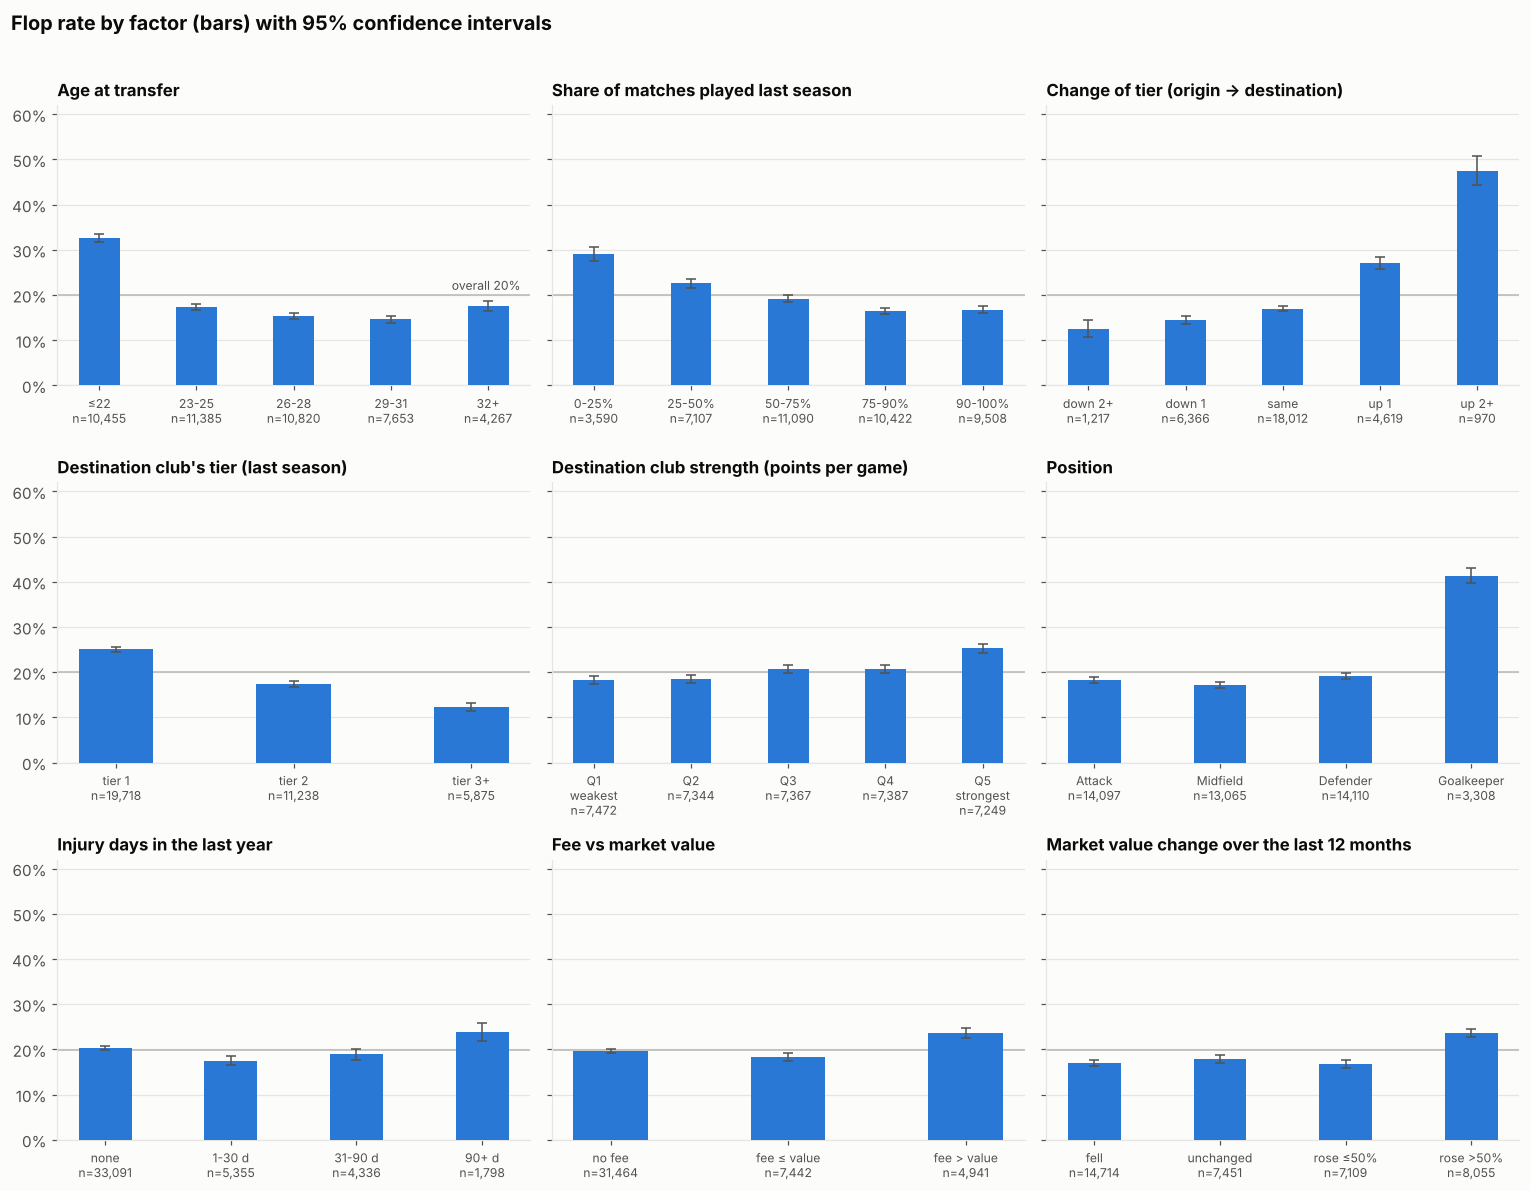

In [4]:
age_cat = pd.cut(age_floor, [0, 22, 25, 28, 31, 60], labels=["≤22", "23-25", "26-28", "29-31", "32+"])
prev_cat = pd.cut(d["prev1_share"], [-0.01, 0.25, 0.5, 0.75, 0.9, 1.0], labels=["0-25%", "25-50%", "50-75%", "75-90%", "90-100%"])
tc = d["tier_change"].clip(-2, 2)
tc_cat = pd.Categorical(tc.map({-2: "down 2+", -1: "down 1", 0: "same", 1: "up 1", 2: "up 2+"}),
                        categories=["down 2+", "down 1", "same", "up 1", "up 2+"], ordered=True)
tier_cat = pd.Categorical(d["dest_tier"].map({1: "tier 1", 2: "tier 2", 3: "tier 3+"}), categories=["tier 1", "tier 2", "tier 3+"], ordered=True)
ppg_cat = pd.qcut(d["dest_ppg"], 5, labels=["Q1\nweakest", "Q2", "Q3", "Q4", "Q5\nstrongest"])
pos_cat = pd.Categorical(d["main_position"], categories=["Attack", "Midfield", "Defender", "Goalkeeper"], ordered=True)
inj_cat = pd.cut(d["inj_days_1y"], [-1, 0, 30, 90, 2000], labels=["none", "1-30 d", "31-90 d", "90+ d"])
pct = np.expm1(d["value_change_12m"])
val_cat = pd.Categorical(np.select([pct.isna(), pct < -0.01, pct <= 0.01, pct <= 0.5], ["na", "fell", "unchanged", "rose ≤50%"], default="rose >50%"),
                         categories=["fell", "unchanged", "rose ≤50%", "rose >50%"], ordered=True)
ftv = d["fee_to_value"]
fee_cat = pd.Categorical(np.select([ftv.isna(), ftv == 0, ftv <= 1], ["na", "no fee", "fee ≤ value"], default="fee > value"),
                         categories=["no fee", "fee ≤ value", "fee > value"], ordered=True)

panels = [("Age at transfer", age_cat), ("Share of matches played last season", prev_cat),
          ("Change of tier (origin → destination)", tc_cat), ("Destination club's tier (last season)", tier_cat),
          ("Destination club strength (points per game)", ppg_cat), ("Position", pos_cat),
          ("Injury days in the last year", inj_cat), ("Fee vs market value", fee_cat),
          ("Market value change over the last 12 months", val_cat)]

fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharey=True)
for ax, (title, cat) in zip(axes.ravel(), panels):
    rate_bars(ax, pd.Series(cat, index=d.index, name="cat"), title)
axes[0, 0].set_ylim(0, 0.62)
axes[0, 0].text(0.98, P0 + 0.012, f"overall {P0:.0%}", transform=axes[0, 0].get_yaxis_transform(),
                ha="right", fontsize=8, color=INK2)
fig.suptitle("Flop rate by factor (bars) with 95% confidence intervals", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.97)); save(fig, "02_flop_rate_by_factor"); plt.show()

**First impressions** (to be tested properly in the next section):

- **Age and tier change look strongest.** Under-23s flop far more often than 26-31 year-olds, and flop rates climb
  steeply the further *up* the pyramid the player steps.
- **Destination club tier / strength:** top-tier clubs and stronger clubs cost more minutes.
- **Goalkeepers** are in a class of their own (about twice the outfield rate).
- **Fee vs market value:** players signed for **more than** their market value flop *more* often in the raw rates —
  the opposite of "you get what you pay for". Whether this survives adjustment is tested below.
- **Injuries:** no consistent raw pattern; only the 90+ days group stands out.

Raw rates mix up overlapping factors (young players also tend to be cheaper and to step up more often), so none of
this is a conclusion yet.

## 4 · Separating the factors: one adjusted model

A **logistic regression** estimates how much each factor changes the odds of a flop *holding the others fixed*.
We use it for **explanation**, not prediction (the predictive model is notebook 03).

- Continuous variables are standardised, so every coefficient reads as *"odds ratio per +1 standard deviation"* and
  effects can be compared with each other.
- Age and destination tier are categories (reference: age 23-29, tier 1).
- An **odds ratio (OR)** above 1 means higher flop odds, below 1 lower; the 95 % interval says how sure we are.
  If it contains 1 the effect is not distinguishable from zero.
- Rows with a missing value in any variable are dropped for this model (see the robustness check right after).

In [5]:
CONT = ["log_value", "prev1_share", "tier_change", "dest_ppg", "fee_to_value", "dest_regulars_same_pos",
        "inj_days_1y", "value_change_12m", "value_to_peak", "years_pro", "n_prior_perm", "prev1_apps_all"]

def fit_adjusted(df, cont, extra_terms):
    need = cont + ["age_grp"] + (["dest_tier"] if extra_terms else [])
    use = df.dropna(subset=need).copy()
    if extra_terms:
        use["dest_tier"] = use["dest_tier"].astype(int)
    for c in cont:
        use["z_" + c] = (use[c] - use[c].mean()) / use[c].std()
    rhs = ['C(age_grp, Treatment("23_29"))', "gk"] + extra_terms + ["z_" + c for c in cont]
    model = smf.logit("y_flop ~ " + " + ".join(rhs), use).fit(disp=0, maxiter=200)
    ci = model.conf_int()
    res = pd.DataFrame({"OR": np.exp(model.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]), "p": model.pvalues})
    return model, res.drop(index="Intercept"), use

m_full, res_full, used_full = fit_adjusted(d, CONT, ['C(dest_tier, Treatment(1))'])
print(f"adjusted model: {len(used_full):,} transfers (of {len(d):,}), {int(used_full.y_flop.sum()):,} flops")

NICE = {
    'C(age_grp, Treatment("23_29"))[T.u23]': "Age ≤ 22 (vs 23-29)",
    'C(age_grp, Treatment("23_29"))[T.30plus]': "Age 30+ (vs 23-29)",
    "C(dest_tier, Treatment(1))[T.2]": "Destination tier 2 (vs tier 1)",
    "C(dest_tier, Treatment(1))[T.3]": "Destination tier 3+ (vs tier 1)",
    "gk": "Goalkeeper",
    "z_log_value": "Market value (log)",
    "z_prev1_share": "Share of matches played last season",
    "z_tier_change": "Step up in tier",
    "z_dest_ppg": "Destination club strength (ppg)",
    "z_fee_to_value": "Fee relative to market value",
    "z_dest_regulars_same_pos": "Regulars at same position at club",
    "z_inj_days_1y": "Injury days, last year",
    "z_value_change_12m": "Market value change, last 12 m",
    "z_value_to_peak": "Value relative to career peak",
    "z_years_pro": "Years as a professional",
    "z_n_prior_perm": "Number of earlier transfers",
    "z_prev1_apps_all": "Appearances last season (all comps)",
}
res_full["label"] = res_full.index.map(NICE)
res_full[["label", "OR", "lo", "hi", "p"]].round(3).reset_index(drop=True)

adjusted model: 26,898 transfers (of 44,580), 4,744 flops


,label,OR,lo,hi,p
0,Age 30+ (vs 23-29),1.010,0.893,1.143,0.872
1,Age ≤ 22 (vs 23-29),1.696,1.538,1.870,0.000
2,Destination tier 2 (vs tier 1),0.730,0.667,0.799,0.000
3,Destination tier 3+ (vs tier 1),0.473,0.410,0.546,0.000
4,Goalkeeper,4.113,3.634,4.656,0.000
5,Market value (log),0.752,0.718,0.787,0.000
6,Share of matches played last season,0.854,0.799,0.913,0.000
7,Step up in tier,1.304,1.249,1.361,0.000
8,Destination club strength (ppg),1.365,1.318,1.413,0.000
9,Fee relative to market value,1.031,0.998,1.065,0.066


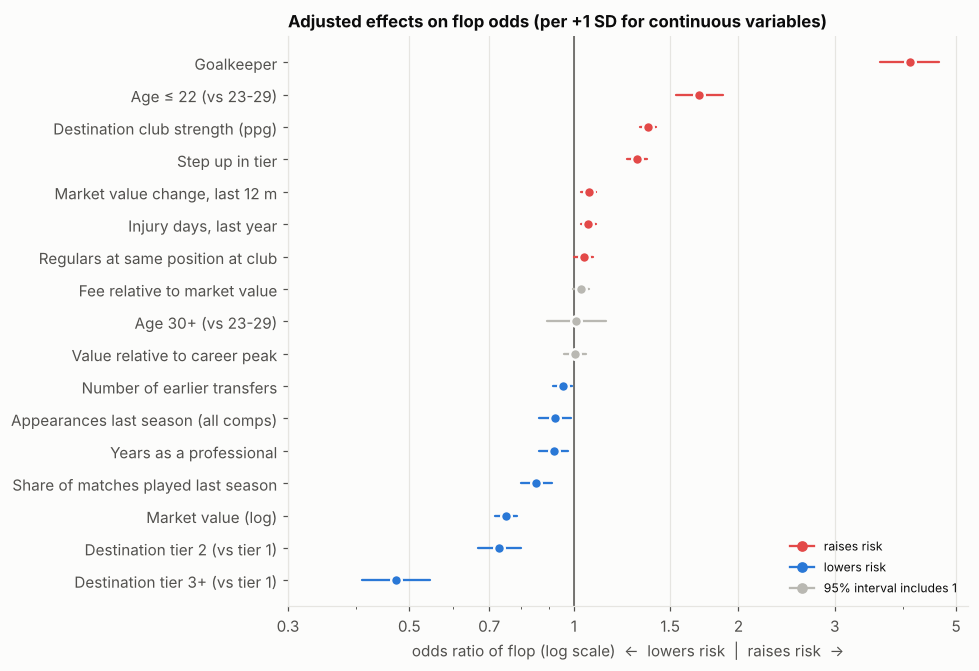

In [6]:
# Forest plot: effect sizes with 95% intervals. Blue = lowers risk, red = raises risk, grey = not distinguishable from 1.
plot = res_full.sort_values("OR").copy()
sig = (plot["lo"] > 1) | (plot["hi"] < 1)
colors = np.where(~sig, GRAY, np.where(plot["OR"] > 1, RED, BLUE))
fig, ax = plt.subplots(figsize=(9, 6.2))
y = np.arange(len(plot))
for yi, (_, r), c in zip(y, plot.iterrows(), colors):
    ax.plot([r["lo"], r["hi"]], [yi, yi], color=c, lw=1.5, solid_capstyle="round", zorder=3)
    ax.plot(r["OR"], yi, "o", color=c, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=4)
ax.axvline(1, color=INK2, lw=1, zorder=2)
ax.set_xscale("log"); ax.set_xticks([0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5])
ax.get_xaxis().set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(y); ax.set_yticklabels(plot["label"]); ax.grid(axis="y", visible=False)
ax.set_xlabel("odds ratio of flop (log scale)  ←  lowers risk  |  raises risk  →")
ax.set_title("Adjusted effects on flop odds (per +1 SD for continuous variables)")
ax.legend(handles=[Line2D([], [], color=RED, marker="o", lw=1.5, label="raises risk"),
                   Line2D([], [], color=BLUE, marker="o", lw=1.5, label="lowers risk"),
                   Line2D([], [], color=GRAY, marker="o", lw=1.5, label="95% interval includes 1")],
          loc="lower right", frameon=False, fontsize=8)
plt.tight_layout(); save(fig, "02_adjusted_odds_ratios"); plt.show()

### 4.1 Hypothesis scorecard
Each hypothesis is judged by its adjusted odds ratio. Because we test nine hypotheses at once, p-values are corrected
for multiple testing (Benjamini-Hochberg `q`); a hypothesis counts as **supported** only if it clears `q < 0.05`
*in the expected direction*.

In [7]:
def raw_gap(h):
    """Raw difference in flop rate (percentage points): high group minus low group, no adjustment."""
    f = d["y_flop"]
    if h == "H1": return f[d.age_grp == "u23"].mean() - f[d.age_grp == "23_29"].mean()
    if h == "H9": return f[d.gk == 1].mean() - f[d.gk == 0].mean()
    if h == "H3": return f[d.tier_change > 0].mean() - f[d.tier_change < 0].mean()       # moving up minus moving down
    col = {"H2": "prev1_share", "H4": "dest_ppg", "H5": "dest_regulars_same_pos",
           "H6": "fee_to_value", "H7": "log_value", "H8": "inj_days_1y"}[h]
    q = d[col].rank(method="first", pct=True)
    return f[q > 0.8].mean() - f[q <= 0.2].mean()          # top fifth minus bottom fifth

H = [  # id, claim, model term, expected direction
    ("H1", "Under-23s flop more",                          'C(age_grp, Treatment("23_29"))[T.u23]', ">"),
    ("H2", "Less playing time last season -> more flops",  "z_prev1_share",                         "<"),
    ("H3", "Stepping up a tier raises risk",               "z_tier_change",                         ">"),
    ("H4", "Stronger destination club raises risk",        "z_dest_ppg",                            ">"),
    ("H5", "More same-position regulars raise risk",       "z_dest_regulars_same_pos",              ">"),
    ("H6", "Paying above market value lowers risk",        "z_fee_to_value",                        "<"),
    ("H7", "Higher-valued players flop less",              "z_log_value",                           "<"),
    ("H8", "Recent injuries raise risk",                   "z_inj_days_1y",                         ">"),
    ("H9", "Goalkeepers flop more",                        "gk",                                    ">"),
]
score = pd.DataFrame([{"id": i, "hypothesis": c, "expected": "OR > 1" if e == ">" else "OR < 1",
                       "raw gap (pp)": 100 * raw_gap(i), **res_full.loc[t, ["OR", "lo", "hi", "p"]].to_dict()}
                      for i, c, t, e in H])
score["q (BH)"] = multipletests(score["p"], method="fdr_bh")[1]
def verdict(r, e):
    right_way = (r["lo"] > 1) if e == ">" else (r["hi"] < 1)
    wrong_way = (r["hi"] < 1) if e == ">" else (r["lo"] > 1)
    if right_way and r["q (BH)"] < 0.05: return "supported"
    if wrong_way and r["q (BH)"] < 0.05: return "opposite effect"
    return "not supported"
score["verdict"] = [verdict(r, e) for (_, r), (_, _, _, e) in zip(score.iterrows(), H)]
score.round(3).to_csv(f"{TAB_DIR}/02_hypothesis_scorecard.csv", index=False)
score.round(3)

,id,hypothesis,expected,raw gap (pp),OR,lo,hi,p,q (BH),verdict
0,H1,Under-23s flop more,OR > 1,16.396,1.696,1.538,1.870,0.000,0.000,supported
1,H2,Less playing time last season -> more flops,OR < 1,-8.296,0.854,0.799,0.913,0.000,0.000,supported
2,H3,Stepping up a tier raises risk,OR > 1,16.411,1.304,1.249,1.361,0.000,0.000,supported
3,H4,Stronger destination club raises risk,OR > 1,6.937,1.365,1.318,1.413,0.000,0.000,supported
4,H5,More same-position regulars raise risk,OR > 1,-4.576,1.042,1.001,1.084,0.045,0.050,not supported
5,H6,Paying above market value lowers risk,OR < 1,3.065,1.031,0.998,1.065,0.066,0.066,not supported
6,H7,Higher-valued players flop less,OR < 1,-6.606,0.752,0.718,0.787,0.000,0.000,supported
7,H8,Recent injuries raise risk,OR > 1,-0.146,1.063,1.029,1.098,0.000,0.000,supported
8,H9,Goalkeepers flop more,OR > 1,23.074,4.113,3.634,4.656,0.000,0.000,supported


**Reading the scorecard**

- **Supported (7 of 9):** under-23 (OR 1.7), little recent playing time, stepping up a tier, a stronger destination club,
  goalkeepers (OR 4.1 — by far the largest effect), lower market value, recent injuries.
- **Age is a "young" effect, not a U-shape:** players aged 30+ are no riskier than 23-29 (OR ≈ 1.0).
- **Not supported — H6 (money buys minutes):** in the raw rates, players bought for more than their market value flop
  *more* (about 24 % vs 18 %). Once age, value, tier and club strength are held fixed, the fee premium has **no
  detectable effect** (OR 1.03, interval includes 1). The raw gap came from the kind of player and club involved,
  not from the price.
- **Not supported — H5 (same-position regulars):** the raw gap points the *wrong* way (−4.6 pp, see the goalkeeper trap
  in section 5); adjusted it is tiny and borderline (OR 1.04, q ≈ 0.05).
- **H8 (injuries) is statistically supported but practically small:** OR 1.06 per standard deviation (about 34 days).
  The raw bars show nothing systematic apart from the 90+ days group. We checked whether age hides an injury effect:
  it does not (age and injury days are almost uncorrelated, and within each age group injured players do not flop more).
- **Exploratory, not in the hypotheses:** players whose market value *rose* in the last 12 months are slightly more
  likely to flop (OR 1.06). Consistent with buying at the peak of the hype, but small and found after the fact, so it
  stays a hypothesis, not a finding.
- Raw gap and adjusted odds ratio need not agree: the raw gap mixes overlapping factors, the OR separates them.
  Where they disagree we trust the adjusted one more, remembering it relies on the model being roughly right.

### 4.2 Robustness: do the conclusions survive keeping the rows we dropped?

In [8]:
# The club-context variables (tier, strength, tier change) are missing for ~30% of transfers. Refit WITHOUT them on all rows
# that have the other variables, and compare the odds ratios of the variables the two models share.
cont_small = [c for c in CONT if c not in ("tier_change", "dest_ppg")]
m_small, res_small, used_small = fit_adjusted(d, cont_small, [])
common = res_full.index.intersection(res_small.index)
def sig_flag(r):
    return np.where((r["lo"] > 1) | (r["hi"] < 1), "yes", "no")
cmp_ = pd.DataFrame({"label": res_full.loc[common, "label"],
                     "OR full model": res_full.loc[common, "OR"], "significant (full)": sig_flag(res_full.loc[common]),
                     "OR without club context": res_small.loc[common, "OR"], "significant (no club ctx)": sig_flag(res_small.loc[common])}).round(3)
print(f"full model n = {len(used_full):,} | model without club context n = {len(used_small):,}")
cmp_.reset_index(drop=True)

full model n = 26,898 | model without club context n = 35,430


,label,OR full model,significant (full),OR without club context,significant (no club ctx)
0,Age 30+ (vs 23-29),1.010,no,1.098,no
1,Age ≤ 22 (vs 23-29),1.696,yes,1.969,yes
2,Goalkeeper,4.113,yes,4.074,yes
3,Market value (log),0.752,yes,0.893,yes
4,Share of matches played last season,0.854,yes,0.923,yes
5,Fee relative to market value,1.031,no,1.029,yes
6,Regulars at same position at club,1.042,yes,1.056,yes
7,"Injury days, last year",1.063,yes,1.065,yes
8,"Market value change, last 12 m",1.064,yes,1.070,yes
9,Value relative to career peak,1.005,no,0.971,no


The main effects keep their direction when about 8,500 more transfers are included: under-23, goalkeeper, injuries and
value change stay clearly significant. Effects that overlap with club strength **shrink** once club context is removed
from the model (market value, last-season playing time), and the under-23 effect grows (1.7 → 2.0) because part of it was
explained by the tier and strength of the club the young players join. That is the expected behaviour, and it tells us
that club context carries real information beyond player features. The fee-to-value effect stays at OR ≈ 1.03 in both models:
if anything a tiny *increase* in risk, never the decrease H6 expected. Conclusions do not hinge on dropping rows with
missing club data.

## 5 · Trap 1 — a pattern that is really something else (confounding)

**Raw pattern:** the fewer established same-position players a club has, the *higher* the flop rate — the opposite of
what H5 expects. **Explanation:** virtually every goalkeeper (99 %) lands in the "0-1" group (a club has one regular goalkeeper), and
goalkeepers flop more than twice as often as outfield players, so that group is one-third goalkeepers and looks risky.
The chart splits the same numbers by position group (groups with fewer than 100 transfers are hidden).

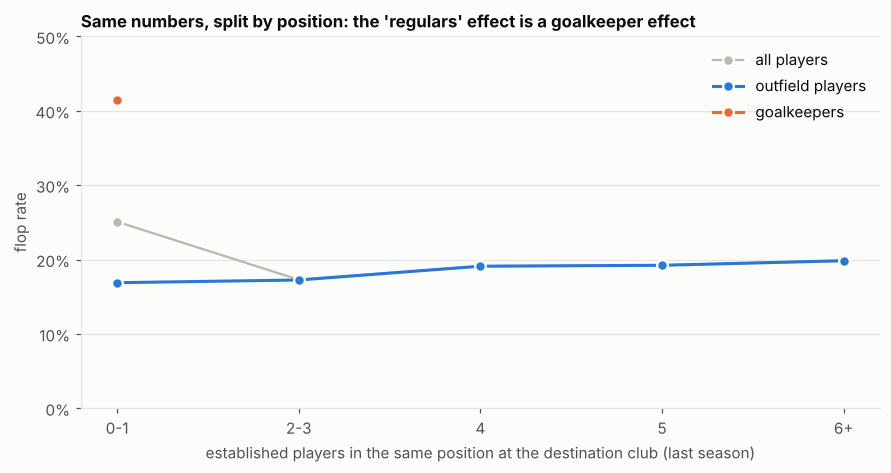

,all players,outfield,goalkeepers,share of goalkeepers in group,transfers (n)
dest_regulars_same_pos,,,,,
0-1,0.251,0.169,0.414,0.334,9801
2-3,0.173,0.172,NaN,0.003,13563
4,0.191,0.191,NaN,0.000,9278
5,0.192,0.192,NaN,0.000,7023
6+,0.198,0.198,NaN,0.000,4915


In [9]:
regs_cat = pd.cut(d["dest_regulars_same_pos"], [-1, 1, 3, 4, 5, 30], labels=["0-1", "2-3", "4", "5", "6+"])
def curve(mask):
    g = d[mask].groupby(regs_cat[mask], observed=True)["y_flop"].agg(k="sum", n="size")
    g["rate"] = g["k"] / g["n"]
    return g.where(g["n"] >= 100)                   # hide groups with fewer than 100 transfers

c_all, c_out, c_gk = curve(d["gk"] >= 0), curve(d["gk"] == 0), curve(d["gk"] == 1)
fig, ax = plt.subplots(figsize=(8.2, 4.4))
for g, col, lab in [(c_all, GRAY, "all players"), (c_out, BLUE, "outfield players"), (c_gk, ORANGE, "goalkeepers")]:
    ax.plot(range(len(g)), g["rate"], "-o", color=col, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label=lab, lw=2 if col != GRAY else 1.5)
ax.set_xticks(range(len(c_all))); ax.set_xticklabels(c_all.index)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0, 0.5); ax.grid(axis="x", visible=False)
ax.set_xlabel("established players in the same position at the destination club (last season)")
ax.set_ylabel("flop rate"); ax.set_title("Same numbers, split by position: the 'regulars' effect is a goalkeeper effect")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); save(fig, "02_trap_goalkeeper_confounding"); plt.show()

summary = pd.DataFrame({"all players": c_all["rate"], "outfield": c_out["rate"], "goalkeepers": c_gk["rate"],
                        "share of goalkeepers in group": d.groupby(regs_cat, observed=True)["gk"].mean(),
                        "transfers (n)": d.groupby(regs_cat, observed=True).size()}).round(3)
summary

Among **outfield players** (blue) the flop rate rises only slightly with the number of established same-position players
— the direction H5 expected, but a small effect. The strong *negative* slope in the grey line is created by the changing
share of goalkeepers in each group (table). Lesson: **always compare within position before reading a
pattern.** This is why position is a mandatory feature, and why the model is also evaluated per position in
notebook 03.

## 6 · Trap 2 — small samples: club-level flop rates are mostly noise

It is tempting to rank destination clubs by their flop rate ("this club wastes signings"). The funnel plot shows
each club's rate against how many transfers it has. If clubs differed only by chance, almost all dots would lie
inside the two grey curves (the 95 % band expected from pure luck at that sample size).

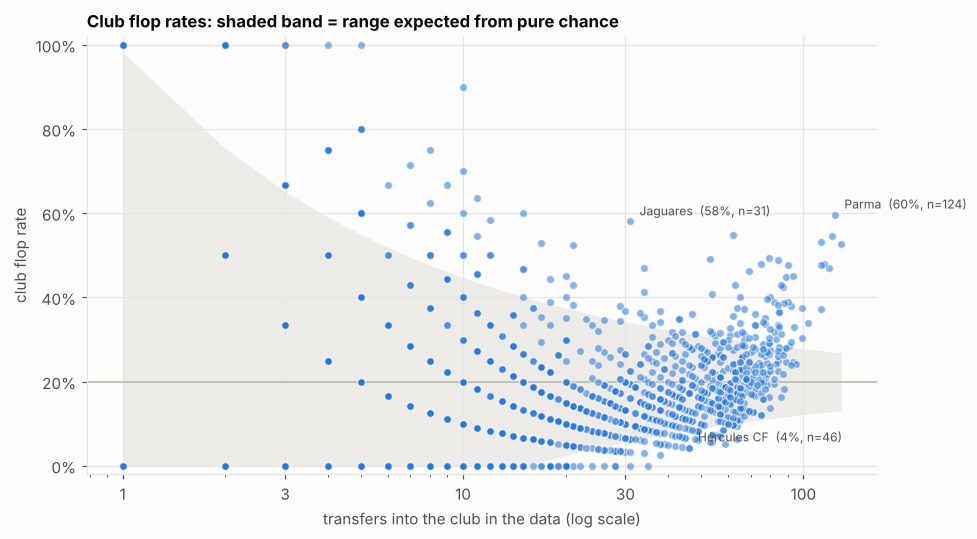

,clubs,share_outside_band
n,,
1-4,1429,0.115
5-14,539,0.069
15-29,294,0.156
30+,561,0.225


In [10]:
club = d.groupby("to_team_id").agg(n=("y_flop", "size"), k=("y_flop", "sum"), name=("to_team_name", "first")).reset_index()
club["rate"] = club["k"] / club["n"]
nn = np.arange(1, club["n"].max() + 1)
band = 1.96 * np.sqrt(P0 * (1 - P0) / nn)
club["outside"] = (club["rate"] < (P0 - 1.96 * np.sqrt(P0 * (1 - P0) / club["n"]))) | \
                  (club["rate"] > (P0 + 1.96 * np.sqrt(P0 * (1 - P0) / club["n"])))

fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(nn, np.clip(P0 - band, 0, 1), np.clip(P0 + band, 0, 1), color=GRID, alpha=0.7, zorder=1, lw=0)
ax.axhline(P0, color=GRAY, lw=1, zorder=2)
ax.scatter(club["n"], club["rate"], s=26, color=BLUE, alpha=0.55, edgecolor=SURFACE, linewidth=0.8, zorder=3)
big = club[club["n"] >= 30].sort_values("rate")
lowest = big.head(10).sort_values("n").tail(1)                           # one low extreme (the largest club among the lowest)
for _, r in pd.concat([lowest, big.tail(2)]).iterrows():                 # label only a few extremes, far apart
    ax.annotate(f"{r['name']}  ({r['rate']:.0%}, n={int(r['n'])})", (r["n"], r["rate"]), xytext=(6, 4),
                textcoords="offset points", fontsize=8, color=INK2)
ax.set_xscale("log"); ax.set_xticks([1, 3, 10, 30, 100]); ax.get_xaxis().set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("transfers into the club in the data (log scale)"); ax.set_ylabel("club flop rate")
ax.set_title("Club flop rates: shaded band = range expected from pure chance")
plt.tight_layout(); save(fig, "02_trap_small_samples_funnel"); plt.show()

size_bucket = pd.cut(club["n"], [0, 4, 14, 29, 1000], labels=["1-4", "5-14", "15-29", "30+"])
club.groupby(size_bucket, observed=True).agg(clubs=("n", "size"), share_outside_band=("outside", "mean")).round(3)

**Reading it.** Clubs with only a handful of transfers show rates anywhere between 0 % and 100 % — that is noise, not
"club quality" (for n < 5 the band is only a rough guide, which is why many tiny clubs sit outside it). Among larger clubs a visibly bigger share than the ~5 % expected by chance lies outside the band, so
**real club differences exist**, but they only become visible with enough transfers. Practical consequences for the
model: (1) do not use raw club flop rates as a feature, they would memorise noise and leak the label; (2) describe
the club through *structural* information (tier, strength, squad depth), as we already do.

## 7 · An interaction worth noticing — the step up hurts the young most

Do the strongest two factors (age and tier change) simply add up, or do they interact? Cells with fewer than 50
transfers are left blank.

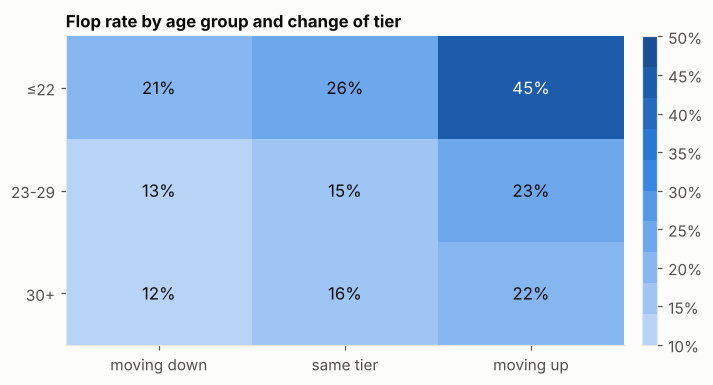

transfers per cell


t,moving down,same tier,moving up
a,,,
≤22,1294,3152,1961
23-29,4412,11304,3056
30+,1877,3556,572


t,moving down,same tier,moving up
a,,,
≤22,0.211,0.255,0.453
23-29,0.132,0.148,0.229
30+,0.117,0.161,0.215


In [11]:
ages3 = pd.Categorical(np.select([age_floor <= 22, age_floor >= 30], ["≤22", "30+"], default="23-29"),
                       categories=["≤22", "23-29", "30+"], ordered=True)
tc3 = pd.Categorical(d["tier_change"].clip(-1, 1).map({-1: "moving down", 0: "same tier", 1: "moving up"}),
                     categories=["moving down", "same tier", "moving up"], ordered=True)
tab = d.assign(a=ages3, t=tc3).pivot_table(index="a", columns="t", values="y_flop", aggfunc=["mean", "size"], observed=True)
rate = tab["mean"].where(tab["size"] >= 50)

cmap = ListedColormap(SEQ_BLUES[1:11])
fig, ax = plt.subplots(figsize=(6.6, 3.6))
im = ax.imshow(rate.values, cmap=cmap, vmin=0.1, vmax=0.5, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(rate.columns); ax.set_yticks(range(3)); ax.set_yticklabels(rate.index)
ax.grid(False)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=11, color="white" if v > 0.3 else INK)
cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.03); cb.ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Flop rate by age group and change of tier")
plt.tight_layout(); save(fig, "02_interaction_age_tier"); plt.show()
print("transfers per cell"); display(tab["size"])
rate.round(3)

Moving **up** a tier raises the flop rate at every age, but most for the youngest: the rate goes from 26 % to 45 %
for players aged ≤22 (+20 percentage points, about 1.8 times), against +8 points for 23-29 and +5 for 30+. A model that
can capture such interactions (e.g. gradient-boosted trees) has something real to learn beyond a simple additive score.

## 8 · Do the drivers hold across time?

A relationship that only existed in 2012-2017 would be useless for 2025 decisions. We recompute the single-rule AUC in
two periods; points close together mean the factor behaves the same way in both.

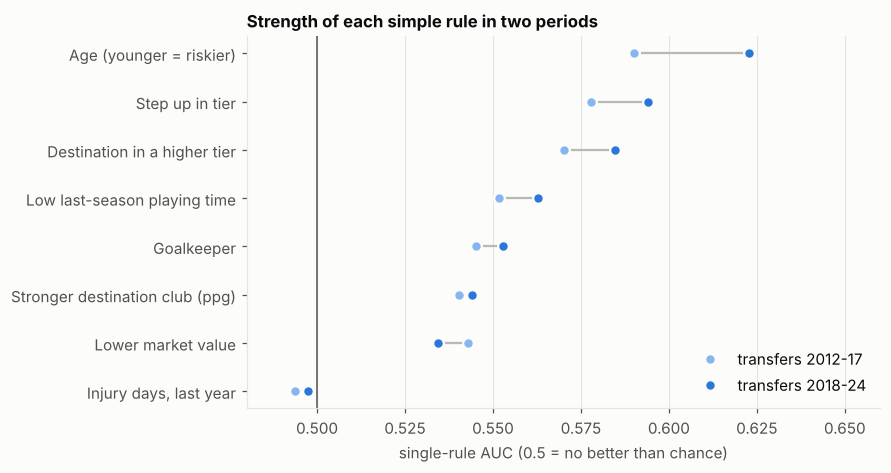

,factor,2012-17,2018-24
0,"Injury days, last year",0.494,0.497
1,Lower market value,0.543,0.534
2,Stronger destination club (ppg),0.540,0.544
3,Goalkeeper,0.545,0.553
4,Low last-season playing time,0.552,0.563
5,Destination in a higher tier,0.570,0.585
6,Step up in tier,0.578,0.594
7,Age (younger = riskier),0.590,0.623


In [12]:
factors = [("Age (younger = riskier)", -d["age"]), ("Low last-season playing time", -d["prev1_share"]),
           ("Step up in tier", d["tier_change"]), ("Stronger destination club (ppg)", d["dest_ppg"]),
           ("Goalkeeper", d["gk"]), ("Lower market value", -d["log_value"]), ("Injury days, last year", d["inj_days_1y"]),
           ("Destination in a higher tier", -d["dest_level"])]
early, late = d["season_y"] <= 2017, d["season_y"] >= 2018
rows = []
for name, s in factors:
    out = {"factor": name}
    for tag, m in [("2012-17", early), ("2018-24", late)]:
        mm = m & s.notna()
        out[tag] = roc_auc_score(d.loc[mm, "y_flop"], s[mm])
    rows.append(out)
stab = pd.DataFrame(rows).sort_values("2018-24")

fig, ax = plt.subplots(figsize=(8.2, 4.4))
yy = np.arange(len(stab))
ax.hlines(yy, stab["2012-17"], stab["2018-24"], color=GRAY, lw=1.5, zorder=2)
ax.plot(stab["2012-17"], yy, "o", color=BLUE_LIGHT, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label="transfers 2012-17", zorder=3)
ax.plot(stab["2018-24"], yy, "o", color=BLUE, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label="transfers 2018-24", zorder=3)
ax.axvline(0.5, color=INK2, lw=1, zorder=1)
ax.set_yticks(yy); ax.set_yticklabels(stab["factor"]); ax.grid(axis="y", visible=False)
ax.set_xlim(0.48, 0.66); ax.set_xlabel("single-rule AUC (0.5 = no better than chance)")
ax.set_title("Strength of each simple rule in two periods"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); save(fig, "02_stability_over_time"); plt.show()
stab.round(3).reset_index(drop=True)

All drivers point the same way in both periods and are of similar strength; age and the tier variables even got somewhat
stronger in 2018-24 (age: 0.59 → 0.62). Injury days alone carry no signal in either period (AUC ≈ 0.5), consistent with
the small adjusted effect. A model trained on older seasons therefore has a fair chance to work on newer ones — which
notebook 03 tests directly with a time-based split.

## 9 · Missing data is itself informative

Some features are missing for a reason: a player without a previous-season record in a European-style league (coming
from abroad or from the lower leagues), a free agent without an origin club, a club without a table position. The
chart compares the flop rate when the information is **missing** versus **present**.

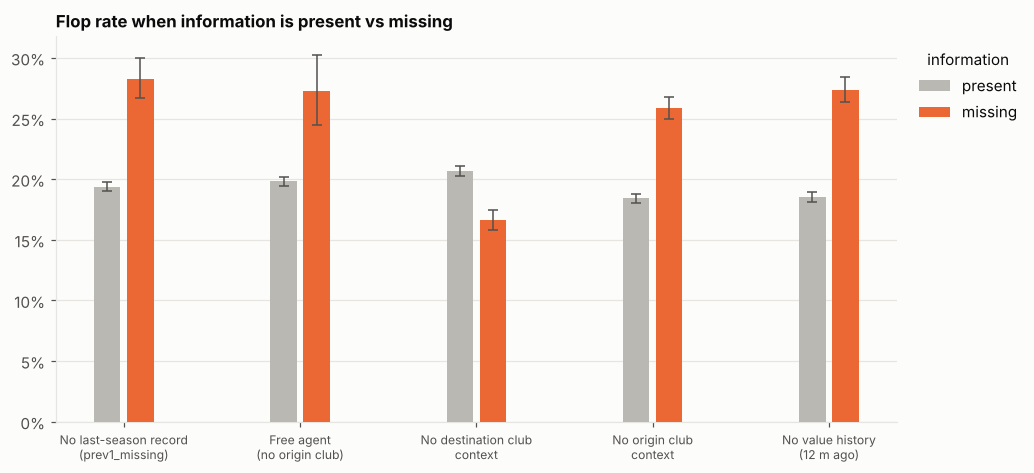

flop rate               n        
state                                    missing present missing present
check                                                                   
Free agent\n(no origin club)               0.273   0.198     906   43674
No destination club\ncontext               0.166   0.207    7749   36831
No last-season record\n(prev1_missing)     0.283   0.194    2863   41717
No origin club\ncontext                    0.259   0.184    9307   35273
No value history\n(12 m ago)               0.274   0.185    7251   37329

In [13]:
checks = {"No last-season record\n(prev1_missing)": d["prev1_share"].isna(),
          "Free agent\n(no origin club)": d["from_no_club"] == 1,
          "No destination club\ncontext": d["dest_level"].isna(),
          "No origin club\ncontext": d["orig_level"].isna(),
          "No value history\n(12 m ago)": d["value_change_12m"].isna()}
rows = []
for name, miss in checks.items():
    for state, m in [("present", ~miss), ("missing", miss)]:
        k, n = int(d.loc[m, "y_flop"].sum()), int(m.sum())
        lo, hi = proportion_confint(k, n, method="wilson")
        rows.append({"check": name, "state": state, "rate": k / n, "lo": lo, "hi": hi, "n": n})
mis = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(len(checks)); w = 0.15
for off, state, col in [(-w / 1.6, "present", GRAY), (w / 1.6, "missing", ORANGE)]:
    s = mis[mis["state"] == state]
    ax.bar(x + off, s["rate"], width=w, color=col, label=state, zorder=3)
    ax.errorbar(x + off, s["rate"], yerr=[s["rate"] - s["lo"], s["hi"] - s["rate"]], fmt="none", ecolor=INK2, elinewidth=1, capsize=3, zorder=4)
ax.set_xticks(x); ax.set_xticklabels(list(checks), fontsize=8)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.grid(axis="x", visible=False)
ax.set_title("Flop rate when information is present vs missing"); ax.legend(frameon=False, title="information", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); save(fig, "02_missingness_vs_outcome"); plt.show()
pd.concat({"flop rate": mis.pivot(index="check", columns="state", values="rate").round(3),
           "n": mis.pivot(index="check", columns="state", values="n")}, axis=1)

In four of the five cases missing information goes with a **higher** flop rate (players arriving from outside the main
data universe are less proven); the exception is a missing destination-club context (a **lower** rate, probably clubs
outside the main leagues). Either way the missing-ness carries signal, so we will not delete these rows or silently fill
them: notebook 03 keeps the missing-flags and uses a model that handles missing values natively.

## 10 · What this means for modelling (notebook 03)

**Findings to carry forward**

1. **Strongest, robust drivers:** goalkeeper, age ≤ 22, destination club tier and strength, step up in tier, market
   value, recent playing time. They hold across time and across label definitions (strength shrinks without the
   zero-appearance rows, see section 2).
2. **Weak or dead ends:** injuries (small), fee relative to market value (none) and "regulars at the position" (tiny)
   — they stay in the feature set (cheap to keep) but we do not expect them to matter.
3. **Interactions exist** (age × tier change), which favours a tree-based model over a plain linear one.

**Baselines the model must beat** (otherwise "AI" adds nothing):
- *Majority guess* — always predict the average flop rate;
- *Single rules* — "age < 23", "low last-season playing time", "step up in tier", each as a risk score;
- *Logistic regression* on the main drivers — what an analyst would build in an afternoon.

**Evaluation design**
- **Time-based split:** train on transfers up to 2019, validate 2020-2021, test 2022-2024. Never shuffle randomly:
  that would let the model learn from the future.
- **Metrics:** ROC-AUC for ranking, PR-AUC and top-decile lift (because only ~20 % are flops), a calibration curve
  (does "30 % risk" really mean 30 %?), and results **per position** and **per tier**.
- **Label robustness:** repeat with the 15 % / 33 % thresholds and **without zero-appearance rows** (the age and
  step-up signal partly comes from young signings who never appear in the main competition).

**Caveats to keep in the final write-up**
- Associations, not causes: "stepping up raises flop odds" does not mean the step *causes* flops; weaker players
  are also the ones who step up.
- Valuation, position and club context come from one website and from a single snapshot.
- Only completed transfers are observed.

*Saved:* figures in `reports/figures/`, scorecard in `reports/tables/02_hypothesis_scorecard.csv`.